In [2]:
# Customer Shopping Behavior — Python Analysis
### Data Cleaning • Feature Engineering • EDA

#**Goal:** Clean and enrich a 3,900-row customer purchase dataset, then prepare it for SQL analysis and Power BI visualisation.

#**Stack:** Python (pandas, seaborn, matplotlib)

#**Deliverable:** `customer_shopping_behavior_clean.csv` with engineered features.

In [3]:
# ─────────────────────────────────────────────────────────────
# Imports and display settings
# ─────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Show all columns when printing dataframes (avoids "..." truncation)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Set a consistent chart style for the whole notebook
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

print("Environment ready.")

Environment ready.


In [7]:
## 1.Load the raw dataset
df = pd.read_csv('customer_shopping_behavior.csv')

# Sanity check: shape and first rows
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head(10)

Rows: 3,900  |  Columns: 18


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually
5,6,46,Male,Sneakers,Footwear,20,Wyoming,M,White,Summer,2.9,Yes,Standard,Yes,Yes,14,Venmo,Weekly
6,7,63,Male,Shirt,Clothing,85,Montana,M,Gray,Fall,3.2,Yes,Free Shipping,Yes,Yes,49,Cash,Quarterly
7,8,27,Male,Shorts,Clothing,34,Louisiana,L,Charcoal,Winter,3.2,Yes,Free Shipping,Yes,Yes,19,Credit Card,Weekly
8,9,26,Male,Coat,Outerwear,97,West Virginia,L,Silver,Summer,2.6,Yes,Express,Yes,Yes,8,Venmo,Annually
9,10,57,Male,Handbag,Accessories,31,Missouri,M,Pink,Spring,4.8,Yes,2-Day Shipping,Yes,Yes,4,Cash,Quarterly


In [6]:
# Column types, non-null counts, memory footprint
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [8]:
## 2. Data Quality Assessment

# Numeric summary: min, quartiles, mean, max for numeric columns
print("─── Numeric summary ───")
display(df.describe().round(2))

# Full summary including categoricals: unique count, top value, frequency
print("\n─── Categorical summary ───")
display(df.describe(include='all').T)   # transpose for readability

─── Numeric summary ───


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.00,3900.00,3900.00,3863.00,3900.00
mean,1950.50,44.07,59.76,3.75,25.35
std,1125.98,15.21,23.69,0.72,14.45
min,1.00,18.00,20.00,2.50,1.00
25%,975.75,31.00,39.00,3.10,13.00
50%,1950.50,44.00,60.00,3.80,25.00
75%,2925.25,57.00,81.00,4.40,38.00
max,3900.00,70.00,100.00,5.00,50.00



─── Categorical summary ───


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,NaN,NaN,NaN,1950.5,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,NaN,NaN,NaN,44.068462,15.207589,18.0,31.0,44.0,57.0,70.0
Gender,3900,2,Male,2652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Purchased,3900,25,Blouse,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3900,4,Clothing,1737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase Amount (USD),3900.0,NaN,NaN,NaN,59.764359,23.685392,20.0,39.0,60.0,81.0,100.0
Location,3900,50,Montana,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,3900,4,M,1755,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,3900,25,Olive,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,3900,4,Spring,999,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Count missing values per column (only show non-zero)
missing = df.isnull().sum()
missing = missing[missing > 0]
print(f"Columns with missing values:\n{missing}")

print(f"\nTotal missing cells: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

Columns with missing values:
Review Rating    37
dtype: int64

Total missing cells: 37
Duplicate rows: 0


In [11]:
## 3. Data Cleaning

# Impute missing Review Rating with the median of its own Category.
# .transform returns same-length series so it aligns back to df rows.
df['Review Rating'] = (
    df.groupby('Category')['Review Rating']
      .transform(lambda x: x.fillna(x.median()))
)

# Verify: no nulls remain
assert df['Review Rating'].isnull().sum() == 0, "Nulls still present"
print(f"✓ Review Rating nulls remaining: {df['Review Rating'].isnull().sum()}")

✓ Review Rating nulls remaining: 0


In [13]:
## 4. Column Standardisation

# Snake-case all column names
df.columns = df.columns.str.lower().str.replace(' ', '_')

# Special case: the "(usd)" suffix is noise — clean it up
df = df.rename(columns={'purchase_amount_(usd)': 'purchase_amount'})

print("New columns:", df.columns.tolist())

# ── Data-quality assertions ──
# These run silently if fine, raise AssertionError if violated.
assert df['age'].between(18, 70).all(),          "Age out of expected range"
assert df['purchase_amount'].between(20, 100).all(), "Purchase amount out of range"
assert df['review_rating'].between(1, 5).all(),  "Rating out of 1-5 range"
assert df['previous_purchases'].between(1, 50).all(), "Previous purchases out of range"
assert df['customer_id'].is_unique,              "Duplicate customer IDs"

New columns: ['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases']


In [15]:
## 5. Redundancy Detection

# Check if the two columns are identical across ALL rows
identical = (df['discount_applied'] == df['promo_code_used']).all()
print(f"Are columns identical? {identical}")

if identical:
    df = df.drop(columns=['promo_code_used'])
    print("✓ Dropped 'promo_code_used' — carries zero extra information.")

print(f"\nCurrent shape: {df.shape}")

Are columns identical? True
✓ Dropped 'promo_code_used' — carries zero extra information.

Current shape: (3900, 17)


In [16]:
## 6. Feature Engineering

# Create 4 equal-sized age buckets using quartiles.
# qcut splits by row-count (each bucket ~975 customers),
# which is better than cut() for customer segmentation.
labels = ['Young Adult', 'Adult', 'Middle-aged', 'Senior']
df['age_group'] = pd.qcut(df['age'], q=4, labels=labels)

# Verify boundaries
print("Age group boundaries and counts:")
print(df.groupby('age_group', observed=True)['age'].agg(['min', 'max', 'count']))

Age group boundaries and counts:
             min  max  count
age_group                   
Young Adult   18   31   1028
Adult         32   44    942
Middle-aged   45   57    986
Senior        58   70    944


In [17]:
# Convert textual purchase frequency to number of days between purchases.
# Note: Bi-Weekly == Fortnightly (14) and Quarterly == Every 3 Months (90),
# so 7 labels collapse to 5 distinct numeric values.
frequency_mapping = {
    'Weekly':           7,
    'Fortnightly':      14,
    'Bi-Weekly':        14,
    'Monthly':          30,
    'Quarterly':        90,
    'Every 3 Months':   90,
    'Annually':         365,
}

df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)

# Verify no unmapped labels remain
assert df['purchase_frequency_days'].isnull().sum() == 0, "Some labels didn't map"
print("✓ Mapping complete. Distinct day values:", sorted(df['purchase_frequency_days'].unique()))

✓ Mapping complete. Distinct day values: [np.int64(7), np.int64(14), np.int64(30), np.int64(90), np.int64(365)]


In [18]:
# Total order count = previous orders + this one
df['total_purchases'] = df['previous_purchases'] + 1

# Approximate customer lifetime value.
# ASSUMPTION: every past order cost the same as this order.
# This is a proxy, not true CLV (we lack historical order values).
df['customer_lifetime_value'] = df['total_purchases'] * df['purchase_amount']

# Quick sanity check
print(df[['previous_purchases', 'total_purchases',
          'purchase_amount', 'customer_lifetime_value']].head())

   previous_purchases  total_purchases  purchase_amount  customer_lifetime_value
0                  14               15               53                      795
1                   2                3               64                      192
2                  23               24               73                     1752
3                  49               50               90                     4500
4                  31               32               49                     1568


In [19]:
# Segment customers into New / Returning / Loyal.
# NOTE: dataset min(previous_purchases) = 1, so 'New' means 1 prior order
# (i.e. 2 total orders). Using == 0 would never match any row.
def assign_loyalty(prev):
    if prev <= 1:
        return 'New'
    elif prev <= 10:
        return 'Returning'
    return 'Loyal'

df['loyalty_tier'] = df['previous_purchases'].apply(assign_loyalty)

print(df['loyalty_tier'].value_counts())

loyalty_tier
Loyal        3116
Returning     701
New            83
Name: count, dtype: int64


In [20]:
# Collapse 7 payment methods into 4 meaningful groups
payment_map = {
    'Credit Card':   'Card',
    'Debit Card':    'Card',
    'PayPal':        'Digital Wallet',
    'Venmo':         'Digital Wallet',
    'Bank Transfer': 'Bank',
    'Cash':          'Cash',
}
df['payment_category'] = df['payment_method'].map(payment_map)

# Verify: no unmapped methods (all 6 originals should be in the dict)
assert df['payment_category'].isnull().sum() == 0, "Unmapped payment method!"
print(df['payment_category'].value_counts())

payment_category
Digital Wallet    1311
Card              1307
Cash               670
Bank               612
Name: count, dtype: int64


In [21]:
# Collapse 50 states into 4 US census regions.
# Map is exhaustive — 9 + 12 + 16 + 13 = 50 states.
region_map = {
    'Northeast': ['Connecticut', 'Maine', 'Massachusetts', 'New Hampshire',
                  'Rhode Island', 'Vermont', 'New Jersey', 'New York', 'Pennsylvania'],
    'Midwest':   ['Illinois', 'Indiana', 'Michigan', 'Ohio', 'Wisconsin', 'Iowa',
                  'Kansas', 'Minnesota', 'Missouri', 'Nebraska', 'North Dakota', 'South Dakota'],
    'South':     ['Delaware', 'Florida', 'Georgia', 'Maryland', 'North Carolina',
                  'South Carolina', 'Virginia', 'West Virginia', 'Alabama', 'Kentucky',
                  'Mississippi', 'Tennessee', 'Arkansas', 'Louisiana', 'Oklahoma', 'Texas'],
    'West':      ['Arizona', 'Colorado', 'Idaho', 'Montana', 'Nevada', 'New Mexico',
                  'Utah', 'Wyoming', 'Alaska', 'California', 'Hawaii', 'Oregon', 'Washington'],
}

# Flatten the dict so state → region
state_to_region = {state: region
                   for region, states in region_map.items()
                   for state in states}

df['region'] = df['location'].map(state_to_region)

# Every state must map; otherwise region will be NaN
assert df['region'].isnull().sum() == 0, "Some states didn't map!"
print(df['region'].value_counts())

region
South        1271
West         1018
Midwest       937
Northeast     674
Name: count, dtype: int64


In [22]:
# Group clothing sizes into Small / Medium / Large for easier analysis
df['size_category'] = df['size'].replace({
    'S':   'Small',
    'XS':  'Small',
    'M':   'Medium',
    'L':   'Large',
    'XL':  'Large',
    'XXL': 'Large',
})

assert df['size_category'].isnull().sum() == 0, "Unmapped size!"
print(df['size_category'].value_counts())

size_category
Medium    1755
Large     1482
Small      663
Name: count, dtype: int64


In [23]:
# Group 25 colours into Warm / Cool / Neutral palettes.
# All 25 colours below are covered — count: 6 + 10 + 9 = 25.
warm_colors    = ['Red', 'Orange', 'Yellow', 'Peach', 'Pink', 'Gold']
cool_colors    = ['Blue', 'Green', 'Teal', 'Turquoise', 'Cyan', 'Indigo',
                  'Violet', 'Lavender', 'Purple', 'Magenta']
neutral_colors = ['Black', 'White', 'Gray', 'Silver', 'Beige', 'Brown',
                  'Charcoal', 'Olive', 'Maroon']

def map_color(c):
    if c in warm_colors:    return 'Warm'
    if c in cool_colors:    return 'Cool'
    if c in neutral_colors: return 'Neutral'
    return 'Other'

df['color_group'] = df['color'].apply(map_color)

# 'Other' should be 0 — all 25 colours are mapped
print(df['color_group'].value_counts())
assert (df['color_group'] == 'Other').sum() == 0, "Some colours unmapped!"

color_group
Cool       1567
Neutral    1417
Warm        916
Name: count, dtype: int64


In [24]:
# Binary flags enable `.mean()` inside groupby for quick "% of group" answers
df['is_discount_user'] = (df['discount_applied']  == 'Yes').astype(int)
df['is_subscriber']    = (df['subscription_status'] == 'Yes').astype(int)

print(f"Subscribers:    {df['is_subscriber'].mean()*100:.1f}%")
print(f"Discount users: {df['is_discount_user'].mean()*100:.1f}%")

Subscribers:    27.0%
Discount users: 43.0%


In [25]:
# How does each customer's spend compare to the average spend in their season?
# season_spend_ratio > 1 means they spent above their season's average.
df['season_avg_spend']   = df.groupby('season')['purchase_amount'].transform('mean')
df['season_spend_ratio'] = (df['purchase_amount'] / df['season_avg_spend']).round(2)

print("Average spend per season:")
print(df.groupby('season')['purchase_amount'].mean().round(2))

Average spend per season:
season
Fall      61.56
Spring    58.74
Summer    58.41
Winter    60.36
Name: purchase_amount, dtype: float64


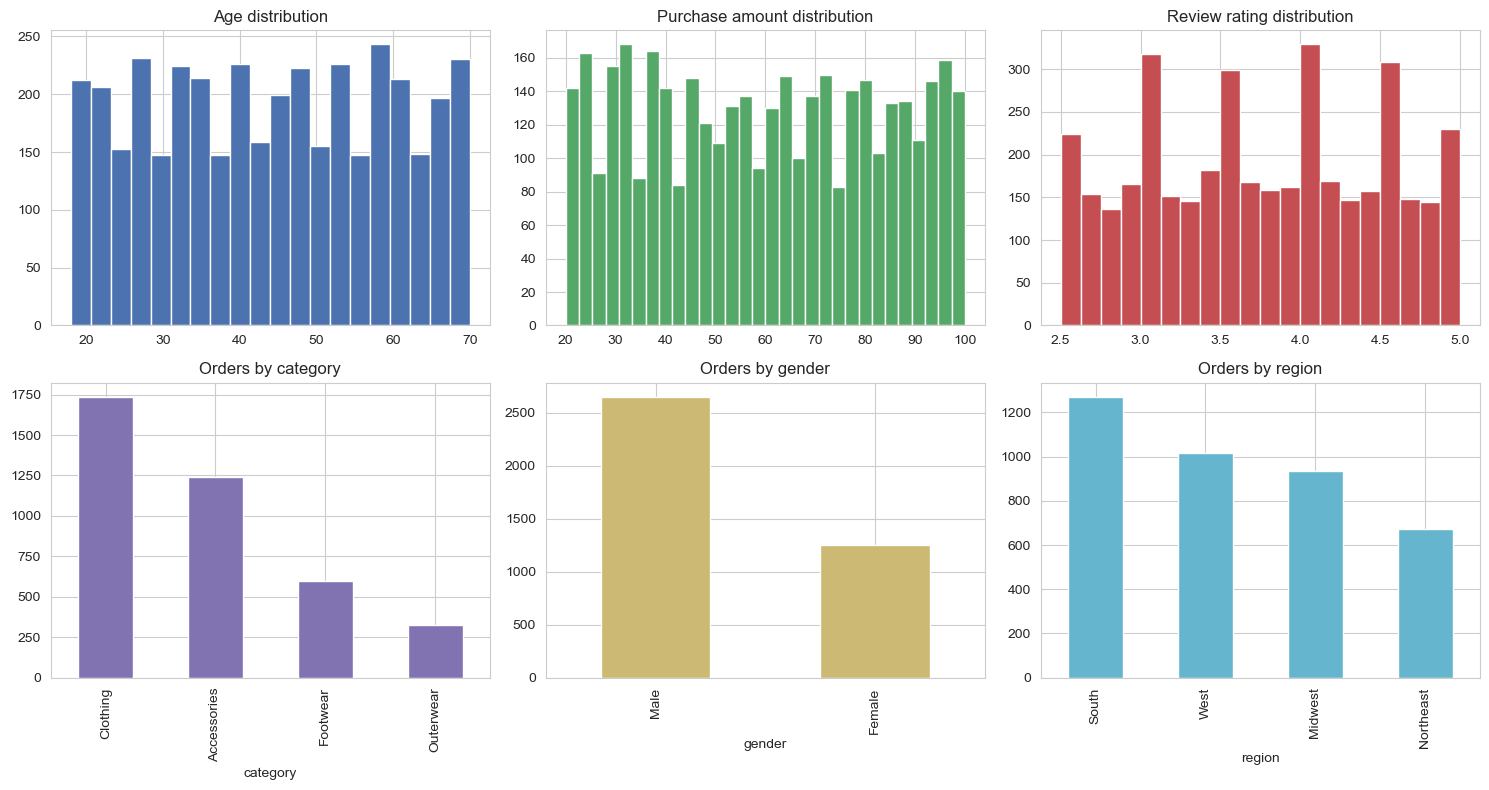

In [26]:
## 7. Exploratory Data Analysis

# 2×3 grid: histograms on top row, bar charts on bottom row.
# Using explicit `ax=` for each plot so every panel shows.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Row 1: histograms
df['age'].hist(bins=20, ax=axes[0, 0], color='#4C72B0')
axes[0, 0].set_title('Age distribution')

df['purchase_amount'].hist(bins=30, ax=axes[0, 1], color='#55A868')
axes[0, 1].set_title('Purchase amount distribution')

df['review_rating'].hist(bins=20, ax=axes[0, 2], color='#C44E52')
axes[0, 2].set_title('Review rating distribution')

# Row 2: bar charts
df['category'].value_counts().plot.bar(ax=axes[1, 0], color='#8172B2')
axes[1, 0].set_title('Orders by category')

df['gender'].value_counts().plot.bar(ax=axes[1, 1], color='#CCB974')
axes[1, 1].set_title('Orders by gender')

df['region'].value_counts().plot.bar(ax=axes[1, 2], color='#64B5CD')
axes[1, 2].set_title('Orders by region')

plt.tight_layout()
plt.show()

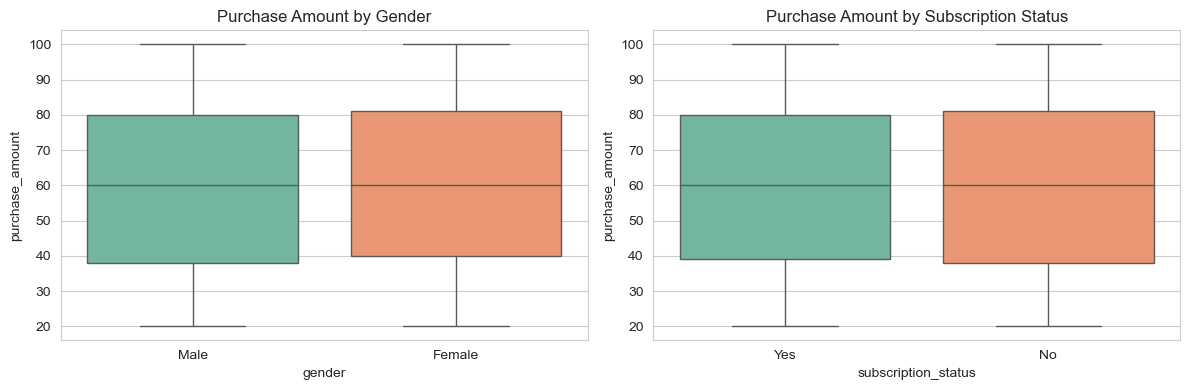

In [28]:
# Boxplots reveal median + spread + outliers across segments
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Assign hue=x and legend=False — satisfies the new seaborn API
# while keeping the same visual (x-axis colored, no extra legend).
sns.boxplot(data=df, x='gender', y='purchase_amount',
            hue='gender', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Purchase Amount by Gender')

sns.boxplot(data=df, x='subscription_status', y='purchase_amount',
            hue='subscription_status', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Purchase Amount by Subscription Status')

plt.tight_layout()
plt.show()

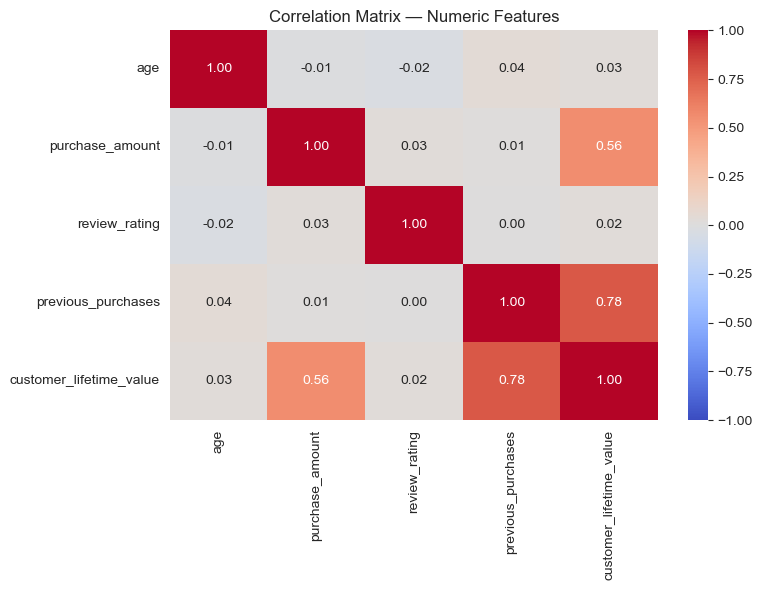

In [30]:
# Correlation matrix for numeric features only
numeric_cols = ['age', 'purchase_amount', 'review_rating',
                'previous_purchases', 'customer_lifetime_value']

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm',
            fmt='.2f', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix — Numeric Features')
plt.tight_layout()
plt.show()

In [31]:
## 8. Headline Numbers

# Snapshot: totals and averages
print(f"Total customers:          {len(df):,}")
print(f"Total current-order revenue: ${df['purchase_amount'].sum():,}")
print(f"Avg purchase (per order):    ${df['purchase_amount'].mean():.2f}")
print(f"Avg review rating:           {df['review_rating'].mean():.2f}")
print(f"Subscribers:                 {df['is_subscriber'].sum():,} ({df['is_subscriber'].mean()*100:.1f}%)")
print(f"Discount users:              {df['is_discount_user'].sum():,} ({df['is_discount_user'].mean()*100:.1f}%)")

print("\n─── Revenue by region ───")
print(df.groupby('region')['purchase_amount']
        .agg(['count', 'sum', 'mean'])
        .round(2)
        .sort_values('sum', ascending=False))

print("\n─── Loyalty tier distribution ───")
print(df['loyalty_tier'].value_counts())

Total customers:          3,900
Total current-order revenue: $233,081
Avg purchase (per order):    $59.76
Avg review rating:           3.75
Subscribers:                 1,053 (27.0%)
Discount users:              1,677 (43.0%)

─── Revenue by region ───
           count    sum   mean
region                        
South       1271  75275  59.23
West        1018  62289  61.19
Midwest      937  55584  59.32
Northeast    674  39933  59.25

─── Loyalty tier distribution ───
loyalty_tier
Loyal        3116
Returning     701
New            83
Name: count, dtype: int64


In [32]:
## 9. Final Validation & Export

# ── Final gate: every expected column present, zero nulls, unique IDs ──
expected_cols = [
    # Original (post-rename, minus dropped promo_code_used)
    'customer_id', 'age', 'gender', 'item_purchased', 'category',
    'purchase_amount', 'location', 'size', 'color', 'season',
    'review_rating', 'subscription_status', 'shipping_type', 'discount_applied',
    'previous_purchases', 'payment_method', 'frequency_of_purchases',
    # Engineered
    'age_group', 'purchase_frequency_days', 'total_purchases',
    'customer_lifetime_value', 'loyalty_tier', 'payment_category',
    'region', 'size_category', 'color_group',
    'is_discount_user', 'is_subscriber',
    'season_avg_spend', 'season_spend_ratio',
]

missing = [c for c in expected_cols if c not in df.columns]
assert not missing, f"Missing expected columns: {missing}"
assert df.isnull().sum().sum() == 0, "Nulls remain"
assert df['customer_id'].is_unique, "Duplicate IDs"

print(f"✅ Shape: {df.shape}")
print(f"✅ All {len(expected_cols)} expected columns present")
print(f"✅ 0 nulls, {df['customer_id'].nunique():,} unique customers")

# ── Export ──
out_path = 'customer_shopping_behavior_clean.csv'
df.to_csv(out_path, index=False)
print(f"\n✓ Exported → {out_path}")

✅ Shape: (3900, 30)
✅ All 30 expected columns present
✅ 0 nulls, 3,900 unique customers

✓ Exported → customer_shopping_behavior_clean.csv


## 10. Assumptions & Limitations

Any real analytical project carries limitations. Documenting them **builds credibility** with reviewers and interviewers. Below are the ones specific to this dataset.

### Data limitations
- **No transaction dates** → no time-series, trend, or seasonality-over-time analysis.
- **`purchase_amount` is a single current order**, not the customer's full transaction history.
- **`previous_purchases` is a count, not a history** → true basket analysis and precise CLV are impossible.
- **`promo_code_used` is 100% identical to `discount_applied`** in this dataset — dropped as redundant. In real retail these typically differ (auto discounts, loyalty discounts exist without promo codes).

### Analytical assumptions
- **`customer_lifetime_value` approximates** by assuming every past order cost the same as this one. Real CLV requires historical order values.
- **`loyalty_tier` "New" = ≤1 previous purchase** (not zero), because the dataset's minimum is 1.
- **`age_group` quartiles are dataset-specific.** If reused on new data, bucket boundaries will shift. For stable production use, replace `pd.qcut` with fixed bins via `pd.cut`.
- **Missing `review_rating` (37 rows, 0.95%)** imputed with category-median — reasonable but still synthetic data.

### Categorical merges
- `Bi-Weekly` = `Fortnightly` = 14 days.
- `Quarterly` = `Every 3 Months` = 90 days.
- Both pairs were collapsed during `purchase_frequency_days` mapping.

### What this dataset CANNOT answer
- Customer acquisition cost, profitability, or margin.
- Cohort retention over time.
- Cart abandonment.
- True RFM (recency is missing).
- Product-level revenue with historical context.

### Next steps
- **SQL phase**: load `customer_shopping_behavior_clean.csv` into mysql, run the 10 core business queries plus ~6 additional insight queries on region, season, payment, discount effectiveness.
- **Power BI phase**: build interactive dashboard with KPI cards, category revenue, region map, age/loyalty slicers.
- **Report + deck**: consolidate insights into 15–20 quantified findings.

In [33]:
pip install pymysql sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [36]:
## 11. Import Data into MySQL

from sqlalchemy import create_engine
from urllib.parse import quote_plus   # safe for passwords with special chars
import pandas as pd

# ── Connection ──
USER     = 'root'
PASSWORD = quote_plus('1234')         # encoded — safe even if password changes
HOST     = 'localhost'
PORT     = 3306                        # MySQL default
DATABASE = 'customer_behavior'

engine = create_engine(
    f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DATABASE}"
)

# ── Test connection before loading (fails fast if credentials are wrong) ──
with engine.connect() as conn:
    from sqlalchemy import text
    version = conn.execute(text("SELECT VERSION();")).scalar()
    print(f"✓ Connected to MySQL {version}")

# ── Load DataFrame into `customer` table ──
df.to_sql(
    name='customer',
    con=engine,
    if_exists='replace',    # drop & recreate on every run — safe while iterating
    index=False,
    chunksize=1000,
)

print(f"✓ Loaded {len(df):,} rows × {df.shape[1]} columns → {DATABASE}.customer")

✓ Connected to MySQL 8.0.44
✓ Loaded 3,900 rows × 30 columns → customer_behavior.customer


In [37]:
df.shape

(3900, 30)

In [38]:
## Verify it actually loaded (separate cell)

# Row count sanity check — must equal 3900
row_count = pd.read_sql("SELECT COUNT(*) AS n FROM customer;", engine)
print(row_count)

# Spot-check: first 5 rows
pd.read_sql("SELECT * FROM customer LIMIT 5;", engine)

      n
0  3900


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days,total_purchases,customer_lifetime_value,loyalty_tier,payment_category,region,size_category,color_group,is_discount_user,is_subscriber,season_avg_spend,season_spend_ratio
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14,15,795,Loyal,Digital Wallet,South,Large,Neutral,1,1,60.357364,0.88
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14,3,192,Returning,Cash,Northeast,Large,Neutral,1,1,60.357364,1.06
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7,24,1752,Loyal,Card,Northeast,Small,Neutral,1,1,58.737738,1.24
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7,50,4500,Loyal,Digital Wallet,Northeast,Medium,Neutral,1,1,58.737738,1.53
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365,32,1568,Loyal,Digital Wallet,West,Medium,Cool,1,1,58.737738,0.83
